Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- TÊN CÁC CỘT CÓ TRONG FILE SPAM.CSV CỦA BẠN ---
['Category', 'Messages']

=> Tự động chọn cột Nhãn: 'Category' | Cột Nội dung văn bản: 'Messages'

--- 5 DÒNG ĐẦU CỦA TẬP DỮ LIỆU ---
  Category                                           Messages
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...

--- KIỂM TRA GIÁ TRỊ THIẾU (NULL) ---
Category    0
Messages    1
dtype: int64

--- PHÂN BỐ SỐ LƯỢNG MỖI NHÃN ---
Category
ham     4823
spam     747
Name: count, dtype: int64


/tmp/ipykernel_650/155641421.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=label_col, palette='viridis')


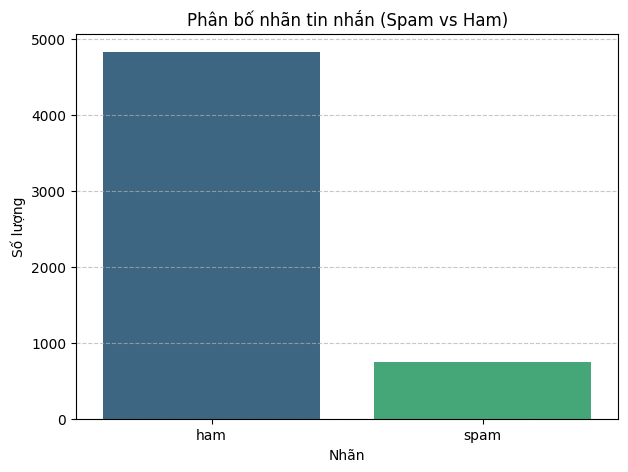


--- SO SÁNH VĂN BẢN TRƯỚC VÀ SAU KHI XỬ LÝ ---
                                            Messages  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go until jurong point crazy available only in ...  
1                            ok lar joking wif u oni  
2  free entry in a wkly comp to win fa cup final ...  
3        u dun say so early hor u c already then say  
4  nah i dont think he goes to usf he lives aroun...  

=== KẾT QUẢ DỮ LIỆU SAU KHI VECTOR HÓA (BAG OF WORDS) ===
Kích thước ma trận đặc trưng (Số văn bản x Số từ vựng): (5570, 1000)

15 từ vựng đầu tiên trong từ điển: ['abiola' 'able' 'abt' 'accept' 'access' 'account' 'actually' 'add'
 'address' 'admirer' 'aft' 'afternoon' 'age' 'ago' 'a

In [3]:
# ==============================================================================
# BƯỚC 1: KẾT NỐI GOOGLE DRIVE VỚI COLAB VÀ KHAI BÁO ĐƯỜNG DẪN
# ==============================================================================
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.feature_extraction.text import CountVectorizer

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Đường dẫn tới file Spam.csv
file_path = '/content/drive/MyDrive/Nhap_Mon_Hoc_May/Buoi4/Spam.csv'

# ==============================================================================
# BƯỚC 2: ĐỌC VÀ TỰ ĐỘNG XÁC ĐỊNH TÊN CỘT TRONG FILE
# ==============================================================================
try:
    df = pd.read_csv(file_path, encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding='latin-1')

print("--- TÊN CÁC CỘT CÓ TRONG FILE SPAM.CSV CỦA BẠN ---")
print(df.columns.tolist())

# Tự động tìm cột chứa nhãn và cột chứa nội dung tin nhắn
label_col = None
text_col = None

# Tìm cột chứa văn bản
for col in df.columns:
    if col.lower() in ['message', 'text', 'sms', 'v2', 'content', 'email']:
        text_col = col
        break

# Tìm cột chứa nhãn
for col in df.columns:
    if col.lower() in ['category', 'label', 'type', 'v1', 'target', 'class']:
        label_col = col
        break

# Nếu không tìm thấy theo tên chuẩn, tự động lấy cột 0 làm nhãn, cột 1 làm văn bản
if text_col is None:
    text_col = df.columns[1] if len(df.columns) > 1 else df.columns[0]
if label_col is None:
    label_col = df.columns[0]

print(f"\n=> Tự động chọn cột Nhãn: '{label_col}' | Cột Nội dung văn bản: '{text_col}'")

print("\n--- 5 DÒNG ĐẦU CỦA TẬP DỮ LIỆU ---")
print(df[[label_col, text_col]].head())

print("\n--- KIỂM TRA GIÁ TRỊ THIẾU (NULL) ---")
print(df[[label_col, text_col]].isnull().sum())

print("\n--- PHÂN BỐ SỐ LƯỢNG MỖI NHÃN ---")
print(df[label_col].value_counts())

# ==============================================================================
# BƯỚC 3: TRỰC QUAN HÓA DỮ LIỆU (DATA VISUALIZATION)
# ==============================================================================
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=label_col, palette='viridis')
plt.title('Phân bố nhãn tin nhắn (Spam vs Ham)')
plt.xlabel('Nhãn')
plt.ylabel('Số lượng')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# ==============================================================================
# BƯỚC 4: TIỀN XỬ LÝ VĂN BẢN (TEXT PREPROCESSING)
# ==============================================================================
def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()  # Chuyển thành chữ thường
    text = re.sub(r'[^a-z\s]', '', text)  # Loại bỏ ký tự đặc biệt, số
    text = re.sub(r'\s+', ' ', text).strip()  # Xóa khoảng trắng thừa
    return text

# Áp dụng tiền xử lý vào cột văn bản vừa tìm được
df['clean_text'] = df[text_col].apply(preprocess_text)

print("\n--- SO SÁNH VĂN BẢN TRƯỚC VÀ SAU KHI XỬ LÝ ---")
print(df[[text_col, 'clean_text']].head())

# ==============================================================================
# BƯỚC 5 & 6: VECTOR HÓA BẰNG BAG OF WORDS VÀ MÔ TẢ DỮ LIỆU SAU KHI CHUYỂN
# ==============================================================================
vectorizer = CountVectorizer(stop_words='english', max_features=1000)
X_bow = vectorizer.fit_transform(df['clean_text'])

print("\n=== KẾT QUẢ DỮ LIỆU SAU KHI VECTOR HÓA (BAG OF WORDS) ===")
print(f"Kích thước ma trận đặc trưng (Số văn bản x Số từ vựng): {X_bow.shape}")

vocab = vectorizer.get_feature_names_out()
print(f"\n15 từ vựng đầu tiên trong từ điển: {vocab[:15]}")

# Hiển thị dạng bảng số 5 dòng đầu tiên
df_vector = pd.DataFrame(X_bow.toarray()[:5], columns=vocab)
print("\n--- MINH HỌA 5 DÒNG DỮ LIỆU DẠNG VECTOR SỐ (10 TỪ ĐẦU TIÊN) ---")
print(df_vector.iloc[:, :10])